In [ ]:
import os

# Create the .kaggle directory if it doesn't exist
!mkdir -p ~/.kaggle/

# Move the kaggle.json file to the .kaggle directory
# Assuming kaggle.json is in /content/kaggle.json as per the file list
!mv /content/kaggle.json ~/.kaggle/

# Set permissions for kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API key setup complete. You can now try running your kaggle command again.")

mv: cannot stat '/content/kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API key setup complete. You can now try running your kaggle command again.


In [ ]:
!kaggle datasets download jocelyndumlao/predicting-honeybee-health-from-hive-and-weather

Dataset URL: https://www.kaggle.com/datasets/jocelyndumlao/predicting-honeybee-health-from-hive-and-weather
License(s): CC0-1.0
  0% 0.00/74.3k [00:00<?, ?B/s]
100% 74.3k/74.3k [00:00<00:00, 230MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os

In [ ]:
!unzip /content/predicting-honeybee-health-from-hive-and-weather.zip

Archive:  /content/predicting-honeybee-health-from-hive-and-weather.zip
  inflating: Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/Apiary_Information.csv  
  inflating: Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/HCC_Inspections.csv  
  inflating: Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/Hive_Information.csv  
  inflating: Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/Hourly_Weather.csv  
  inflating: Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/Weather_Observations.csv  
  inflating: Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/Weather_Stations.csv  


In [ ]:
!ls "Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/"

Apiary_Information.csv	Hive_Information.csv  Weather_Observations.csv
HCC_Inspections.csv	Hourly_Weather.csv    Weather_Stations.csv


In [ ]:
dataset_root = "/content/Predicting Honeybee Health The Healthy Colony Checklist,Hive Scale and Weather Data/"

In [ ]:
apiary_df = pd.read_csv(f'{dataset_root}Apiary_Information.csv')
hive_df = pd.read_csv(f'{dataset_root}Hive_Information.csv')
inspection_df = pd.read_csv(f'{dataset_root}HCC_Inspections.csv')
weather_obs_df = pd.read_csv(f'{dataset_root}Weather_Observations.csv')
hourly_weather_df = pd.read_csv(f'{dataset_root}Hourly_Weather.csv')
stations_df = pd.read_csv(f'{dataset_root}Weather_Stations.csv')

In [ ]:
hive_merged = hive_df.merge(apiary_df, on='ApiaryID', how='left')
inspect_merged = inspection_df.merge(hive_merged, on='HiveID', how='left')
inspect_merged['InsptDate'] = pd.to_datetime(inspect_merged['InsptDate'])

In [ ]:
weather_obs_df['Date'] = pd.to_datetime(weather_obs_df['Date'])
weather_obs_df['Hour'] = pd.to_numeric(weather_obs_df['Obs_Hour'], errors='coerce')

weather_full = weather_obs_df.merge(hourly_weather_df, on='ObsID', how='left')
weather_full = weather_full.merge(stations_df, on='StationID', how='left')
weather_full['Date'] = pd.to_datetime(weather_full['Date'])

In [ ]:
def clean_weather_column(series):
    def to_mean(val):
        if isinstance(val, str):
            try:
                nums = [float(x) for x in val.strip().split()]
                return np.mean(nums) if nums else np.nan
            except:
                return np.nan
        elif isinstance(val, (int, float)):
            return val
        return np.nan
    return series.apply(to_mean)

for col in ['Temperature', 'Humidity', 'Wind_Speed', 'Pressure', 'Dew_Point']:
    weather_full[col] = clean_weather_column(weather_full[col])

In [ ]:
daily_weather = weather_full.groupby(['Date', 'Station_City']).agg({
    'Temperature': 'mean',
    'Humidity': 'mean',
    'Wind_Speed': 'mean',
    'Pressure': 'mean',
    'Dew_Point': 'mean'
}).reset_index()

In [ ]:
final_df = inspect_merged.merge(
    daily_weather,
    left_on=['InsptDate', 'City'],
    right_on=['Date', 'Station_City'],
    how='left'
)
final_df.drop(columns=['Date', 'InpsectionID', 'HiveID', 'ApiaryID', 'Station_City'], inplace=True)

In [ ]:
final_df.select_dtypes('object')

,Healthy,Hive_Tag,Apiary,City,State
0,No,H003-P2,BBCC,Durham,NC
1,No,H003-P2,BBCC,Durham,NC
2,Yes,H003-P2,BBCC,Durham,NC
3,Yes,H003-P2,BBCC,Durham,NC
4,No,H003-P2,BBCC,Durham,NC
...,...,...,...,...,...
2399,No,8,Walker-Cove,Salt Lake City,UT
2400,No,8,Walker-Cove,Salt Lake City,UT
2401,No,8,Walker-Cove,Salt Lake City,UT
2402,No,8,Walker-Cove,Salt Lake City,UT


In [ ]:
final_df['Healthy'] = pd.get_dummies(final_df['Healthy'], drop_first=True)

In [ ]:
final_df.columns

Index(['InsptDate', 'Brood', 'Bees', 'Queen', 'Food', 'Stressors', 'Space',
       'Percent_Met', 'Healthy', 'Hive_Tag', 'Apiary', 'City', 'State',
       'Temperature', 'Humidity', 'Wind_Speed', 'Pressure', 'Dew_Point'],
      dtype='object')

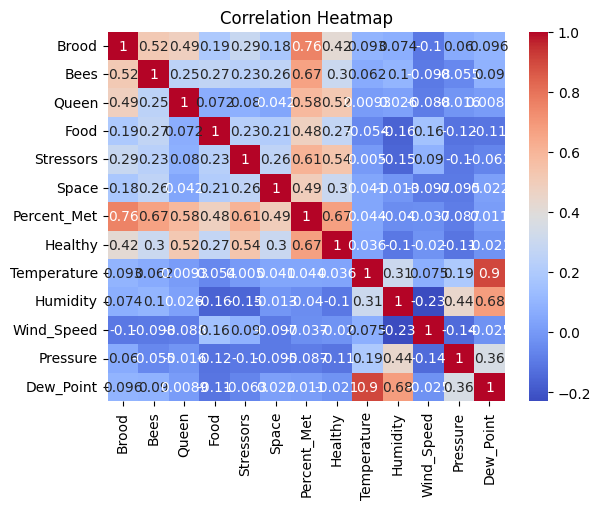

In [ ]:
sns.heatmap(final_df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
final_df = final_df.dropna(subset=['Bees'])  # target must be present
target = 'Bees'
features = [
     'Temperature', 'Humidity', 'Pressure',
    'Brood', 'Queen', 'Food', 'Stressors', 'Space' # 'City', 'State', 'Wind_Speed', 'Dew_Point',
]

X = final_df[features]
y = final_df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

In [ ]:
# categorical_features = ['City', 'State']
numeric_features = [
    'Temperature',
    'Humidity',
    'Pressure',
    #'Dew_Point',
    # 'Wind_Speed',
    # 'Brood',
    'Queen',
    'Food',
    'Stressors',
    'Space'
    ]

from sklearn.impute import SimpleImputer

# Impute missing numeric values with median, then scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Impute missing categorical values with 'missing', then one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both in a ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    # ('cat', categorical_transformer, categorical_features)
])

In [ ]:
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [ ]:
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Stacked Model Test Accuracy: {acc:.3f}")

Stacked Model Test Accuracy: 0.893


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[ 20  45]
 [  6 407]]
              precision    recall  f1-score   support

           0       0.77      0.31      0.44        65
           1       0.90      0.99      0.94       413

    accuracy                           0.89       478
   macro avg       0.83      0.65      0.69       478
weighted avg       0.88      0.89      0.87       478



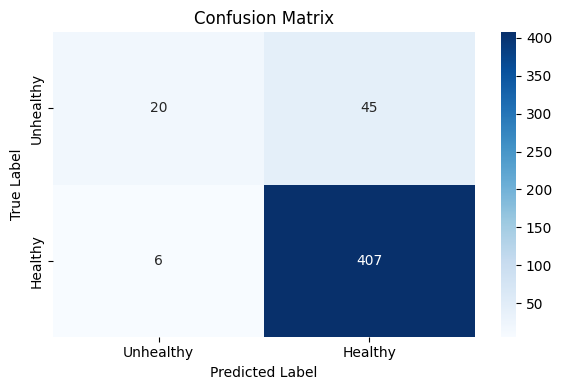

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Unhealthy', 'Healthy'],
            yticklabels=['Unhealthy', 'Healthy'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

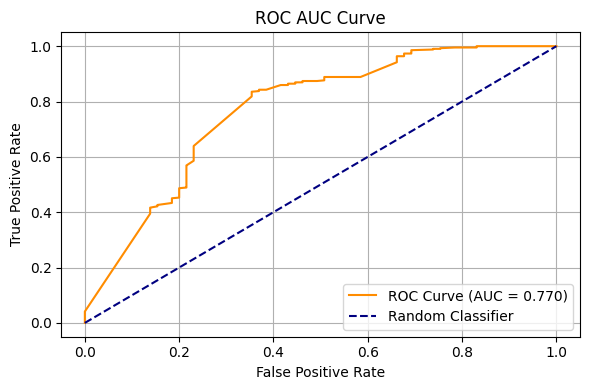

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for the positive class (1 = Healthy)
y_proba = pipeline.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

# Plot ROC Curve
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC AUC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
log_reg = pipeline.named_steps['classifier']

weights = log_reg.coef_
bias = log_reg.intercept_

print("Weights:", weights)
print("Bias:", bias)

Weights: [[ 0.10512709  0.34530639 -0.10919347  0.69434246  0.40673745  0.44313059
   0.33092272]]
Bias: [2.30177151]


In [ ]:
pipeline.steps

[('preprocessor',
  ColumnTransformer(transformers=[('num',
                                   Pipeline(steps=[('imputer',
                                                    SimpleImputer(strategy='median')),
                                                   ('scaler', StandardScaler())]),
                                   ['Temperature', 'Humidity', 'Pressure',
                                    'Queen', 'Food', 'Stressors', 'Space'])])),
 ('classifier', LogisticRegression(max_iter=1000))]

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rfc = RandomForestClassifier(n_estimators=100, random_state=42)

In [ ]:
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)

In [ ]:
acc = accuracy_score(y_test, y_pred)

print(f"Random Forest Test Accuracy: {acc:.3f}")

Random Forest Test Accuracy: 0.902


In [ ]:
import pickle
pickle.dump(log_reg, open('model_lr.pkl', 'wb'))
pickle.dump(rfc, open('model_rfc.pkl', 'wb'))

48